In [129]:
import numpy as np
import pandas as pd

# 划分训练集与测试集
from sklearn.model_selection import train_test_split
# 标准化
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
# 优化器
import torch.optim as optim

In [130]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Noto Sans CJK SC']
plt.rcParams['figure.dpi'] = 150   # Notebook 中显示的清晰度
plt.rcParams['savefig.dpi'] = 300  # 保存图片的清晰度
plt.rcParams['font.size'] = 12

In [131]:
data = np.load('mnist.npz')
print(data.files)

['x_test', 'x_train', 'y_train', 'y_test']


In [132]:
x_train, x_test, y_train, y_test = data['x_train'], data['x_test'], data['y_train'], data['y_test']
print(f"训练集形状: {x_train.shape}")
print(f"测试集形状: {x_test.shape}")

训练集形状: (60000, 28, 28)
测试集形状: (10000, 28, 28)


In [133]:
x_train = x_train.reshape((60000, 28 * 28))
x_test = x_test.reshape((10000, 28 * 28))
print(f"训练集形状: {x_train.shape}")
print(f"测试集形状: {x_test.shape}")

x_train = x_train.astype('float32') / 255
x_test = x_test.astype('float32') / 255

训练集形状: (60000, 784)
测试集形状: (10000, 784)


In [134]:
x_train_tensor = torch.tensor(x_train, dtype = torch.float32)
x_test_tensor = torch.tensor(x_test, dtype = torch.float32)

y_train_tensor = torch.tensor(y_train, dtype = torch.long)
y_test_tensor = torch.tensor(y_test, dtype = torch.long)

In [135]:
# 自定义网络结构
class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.fc1 = nn.Linear(784, 512) # 输入层 784 -> 隐藏层 512
        self.out = nn.Linear(512, 10) # 隐藏层 512 -> 输出层 10
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.out(x)  # 直接输出线性结果
        return x

In [136]:
model = Net() # 定义模型
criterion = nn.CrossEntropyLoss() # 损失函数（交叉熵损失）
optimizer = optim.Adam(model.parameters(), lr = 0.01) # 优化器

In [137]:
model.train() # 将模型切换到训练状态

epochs = 150
result_history = []

for epoch in range(epochs):
    optimizer.zero_grad() # 梯度清零
    preds_train_y = model(x_train_tensor) # 前向传播
    loss_train = criterion(preds_train_y, y_train_tensor) # 计算损失
    loss_train.backward() # 反向传播（自动求导 并 累加梯度）
    optimizer.step() # 根据求导计算出的 梯度，更新模型参数
    
    result_history.append(loss_train.item()) # 记录损失
    
    print(f"训练进度: {epoch+1}/{epochs}, 训练集loss: {loss_train.item():.4f}")

训练进度: 1/150, 训练集loss: 2.3079
训练进度: 2/150, 训练集loss: 1.4718
训练进度: 3/150, 训练集loss: 1.0200
训练进度: 4/150, 训练集loss: 0.7828
训练进度: 5/150, 训练集loss: 0.6610
训练进度: 6/150, 训练集loss: 0.5859
训练进度: 7/150, 训练集loss: 0.4743
训练进度: 8/150, 训练集loss: 0.4910
训练进度: 9/150, 训练集loss: 0.4524
训练进度: 10/150, 训练集loss: 0.3866
训练进度: 11/150, 训练集loss: 0.3641
训练进度: 12/150, 训练集loss: 0.3616
训练进度: 13/150, 训练集loss: 0.3510
训练进度: 14/150, 训练集loss: 0.3268
训练进度: 15/150, 训练集loss: 0.3023
训练进度: 16/150, 训练集loss: 0.2818
训练进度: 17/150, 训练集loss: 0.2693
训练进度: 18/150, 训练集loss: 0.2679
训练进度: 19/150, 训练集loss: 0.2611
训练进度: 20/150, 训练集loss: 0.2424
训练进度: 21/150, 训练集loss: 0.2252
训练进度: 22/150, 训练集loss: 0.2166
训练进度: 23/150, 训练集loss: 0.2116
训练进度: 24/150, 训练集loss: 0.2047
训练进度: 25/150, 训练集loss: 0.1964
训练进度: 26/150, 训练集loss: 0.1893
训练进度: 27/150, 训练集loss: 0.1826
训练进度: 28/150, 训练集loss: 0.1748
训练进度: 29/150, 训练集loss: 0.1681
训练进度: 30/150, 训练集loss: 0.1631
训练进度: 31/150, 训练集loss: 0.1577
训练进度: 32/150, 训练集loss: 0.1522
训练进度: 33/150, 训练集loss: 0.1468
训练进度: 34/150, 训练集lo

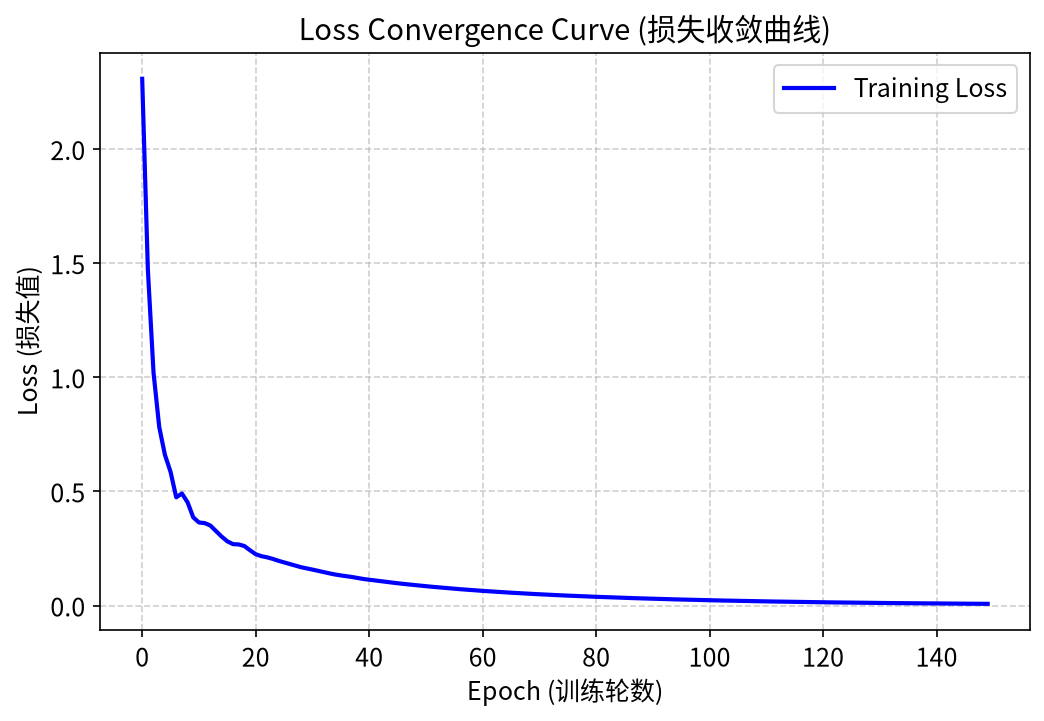

In [138]:
# 绘制loss曲线，查看收敛情况
plt.figure(figsize=(8, 5))  # 设置画布大小，宽8，高5
plt.plot(result_history, label='Training Loss', color='blue', linewidth=2)

# 添加标签
plt.title('Loss Convergence Curve (损失收敛曲线)', fontsize=14)
plt.xlabel('Epoch (训练轮数)', fontsize=12)
plt.ylabel('Loss (损失值)', fontsize=12)

plt.grid(True, linestyle='--', alpha=0.6)  # 添加网格线，方便看数值
plt.legend(fontsize=12)  # 显示图例

plt.show()

In [139]:
model.eval() # 将模型切换到测试状态

with torch.no_grad(): # 关闭梯度计算
    test_preds = model(x_test_tensor)
    test_loss = criterion(test_preds, y_test_tensor)
    predicted_classes = torch.argmax(test_preds, dim=1)
    correct = (predicted_classes == y_test_tensor).sum().item()

    accuracy = correct / y_test_tensor.size(0)

print(f"测试集损失 (Test Loss): {test_loss.item():.4f}")
print(f"测试集准确率 (Test Accuracy): {accuracy * 100:.2f}%  ({correct}/{y_test_tensor.size(0)})")

测试集损失 (Test Loss): 0.0782
测试集准确率 (Test Accuracy): 97.71%  (9771/10000)
